 # 01. EDA - разведочный анализ

Разведочный анализ трёх датасетов:
- **Credit Risk** - бинарная классификация, таргет `loan_status`
- **Telco Churn** - бинарная классификация, таргет `Churn`
- **Store Item Demand** - регрессия (временной ряд), таргет `sales`

Цель: понять структуру данных, типы колонок, пропуски, дисбаланс классов,
кардинальность категориальных признаков.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_style('whitegrid')

config = Config()
RANDOM_STATE = config.RANDOM_STATE
print(config)

Config(mode='local', credit='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\credit_risk_dataset.csv', churn='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\train.csv', random_state=42)


## Загрузка датасетов

In [2]:
df_credit = pd.read_csv(config.path_credit)
df_churn = pd.read_csv(config.path_churn)
df_demand = pd.read_csv(config.path_demand)

print("credit:", df_credit.shape)
print("churn: ", df_churn.shape)
print("demand:", df_demand.shape)

credit: (32581, 12)
churn:  (7043, 21)
demand: (913000, 4)


Проверяем:
- `shape` - размер таблицы (строки * колонки);
- `dtypes` - сколько колонок каждого типа (`int64`, `float64`, `object`);
- `columns` - имена признаков и таргета;
- `missing` - где есть пропуски и сколько.

In [3]:
for name, df in [('credit', df_credit), ('churn', df_churn), ('demand', df_demand)]:
    print(f"========== {name} ==========")
    print(f"shape: {df.shape}")
    print(f"dtypes:\n{df.dtypes.value_counts()}")
    print(f"columns: {df.columns.tolist()}")
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f"missing:\n{miss if len(miss) else 'нет пропусков'}")
    print()

========== credit ==========
shape: (32581, 12)
dtypes:
int64      5
str        4
float64    3
Name: count, dtype: int64
columns: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']
missing:
person_emp_length     895
loan_int_rate        3116
dtype: int64

========== churn ==========
shape: (7043, 21)
dtypes:
str        18
int64       2
float64     1
Name: count, dtype: int64
columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
missing:
нет пропусков

========== demand ==========
shape: (913000, 4)
dtypes:
int64    3
str      1
Name

## Таргеты и дисбаланс классов

In [4]:
print("=== credit: loan_status ===")
print(df_credit['loan_status'].value_counts())
print(df_credit['loan_status'].value_counts(normalize=True).round(4))

print("\n=== churn: Churn ===")
print(df_churn['Churn'].value_counts())
print(df_churn['Churn'].value_counts(normalize=True).round(4))

print("\n=== demand: head/tail ===")
print(df_demand.head())
print(df_demand.tail())

=== credit: loan_status ===
loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    0.7818
1    0.2182
Name: proportion, dtype: float64

=== churn: Churn ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

=== demand: head/tail ===
         date  store  item  sales
0  2013-01-01      1     1     13
1  2013-01-02      1     1     11
2  2013-01-03      1     1     14
3  2013-01-04      1     1     13
4  2013-01-05      1     1     10
              date  store  item  sales
912995  2017-12-27     10    50     63
912996  2017-12-28     10    50     59
912997  2017-12-29     10    50     74
912998  2017-12-30     10    50     62
912999  2017-12-31     10    50     82


## Категориальные признаки и числовые статистики

**Кардинальность** - число уникальных значений:
- 2–10 -> OneHot безопасен;
- 100+ -> OneHot раздуёт датасет.

`describe()` - статистика числовых колонок. Ищем выбросы (`max`) и масштаб.

In [5]:
for name, df in [('credit', df_credit), ('churn', df_churn), ('demand', df_demand)]:
    print(f"========== {name} ==========")
    cat_cols = df.select_dtypes(include=['object', 'str']).columns
    print(f"категориальные ({len(cat_cols)}): {cat_cols.tolist()}")
    for c in cat_cols:
        n = df[c].nunique()
        print(f"  {c}: {n} уникальных -> {df[c].unique()[:8]}")
    print(f"\ndescribe (числовые):")
    print(df.describe().T)
    print()

========== credit ==========
категориальные (4): ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
  person_home_ownership: 4 уникальных -> <StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
  loan_intent: 6 уникальных -> <StringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str
  loan_grade: 7 уникальных -> <StringArray>
['D', 'B', 'C', 'A', 'E', 'F', 'G']
Length: 7, dtype: str
  cb_person_default_on_file: 2 уникальных -> <StringArray>
['Y', 'N']
Length: 2, dtype: str

describe (числовые):
                              count          mean           std      min  \
person_age                  32581.0     27.734600      6.348078    20.00   
person_income               32581.0  66074.848470  61983.119168  4000.00   
person_emp_length           31686.0      4.789686      4.142630     0.00   
loan_amnt                   32581.0   

## Качество данных: невозможные значения, дубликаты, «скрытые» пропуски

`describe()` показывает только `NaN`. Но ошибки бывают и другие:

- **невозможные значения** - возраст 144 года, стаж 123 года;
- **логические противоречия** - стаж больше, чем `возраст − 14`;
- **дубликаты строк** - одна и та же строка может попасть и в train, и в test;
- **«скрытые» пропуски** - пустая строка `' '` вместо числа (`TotalCharges`), из-за неё колонка читается как текст;
- **информативные пропуски** - если у строк с пропуском другая доля таргета, удалять их нельзя.

In [6]:
print("========== credit ==========")
print(f"person_age > 100:                    {(df_credit['person_age'] > 100).sum()}")
print(f"person_emp_length > person_age - 14: {(df_credit['person_emp_length'] > df_credit['person_age'] - 14).sum()}")
print(f"полных дубликатов строк:             {df_credit.duplicated().sum()}")
for col in ['person_emp_length', 'loan_int_rate']:
    m = df_credit[col].isna()
    print(f"доля дефолтов: при NaN в {col:18} {df_credit.loc[m, 'loan_status'].mean():.3f} "
          f"(в среднем {df_credit['loan_status'].mean():.3f})")

print("\n========== churn ==========")
tc = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')
print(f"TotalCharges - не число (пробел): {tc.isna().sum()}, tenure у них: {df_churn.loc[tc.isna(), 'tenure'].unique().tolist()}")
print(f"совпадающих строк без customerID: {df_churn.drop(columns='customerID').duplicated().sum()}")

print("\n========== demand ==========")
n_pairs = df_demand.groupby(['store', 'item']).ngroups
print(f"пар (store, item): {n_pairs}, дней: {df_demand['date'].nunique()}, "
      f"строк {len(df_demand)} = {n_pairs} × {df_demand['date'].nunique()}: {len(df_demand) == n_pairs * df_demand['date'].nunique()}")
print(f"нулевых продаж: {(df_demand['sales'] == 0).sum()}")

========== credit ==========
person_age > 100:                    5
person_emp_length > person_age - 14: 2
полных дубликатов строк:             165
доля дефолтов: при NaN в person_emp_length  0.315 (в среднем 0.218)
доля дефолтов: при NaN в loan_int_rate      0.207 (в среднем 0.218)

========== churn ==========
TotalCharges - не число (пробел): 11, tenure у них: [0]
совпадающих строк без customerID: 22

========== demand ==========
пар (store, item): 500, дней: 1826, строк 913000 = 500 × 1826: True
нулевых продаж: 1


## Визуализация: credit

Три графика:
- распределение таргета `loan_status`;
- гистограмма `person_age` - ищем выбросы (до 144 лет);
- гистограмма `loan_int_rate` - проверяем разумность значений.

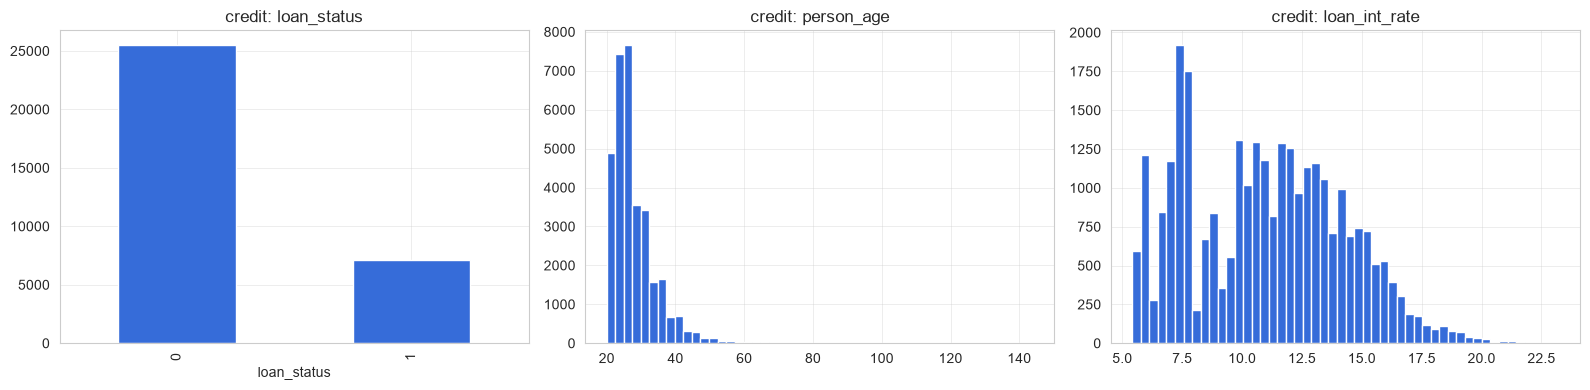

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_credit['loan_status'].value_counts().plot(kind='bar', ax=axes[0], title='credit: loan_status')
df_credit['person_age'].hist(bins=50, ax=axes[1])
axes[1].set_title('credit: person_age')
df_credit['loan_int_rate'].hist(bins=50, ax=axes[2])
axes[2].set_title('credit: loan_int_rate')

plt.tight_layout()
plt.show()

## Визуализация: churn

Сравниваем распределение признаков между классами через boxplot.
Если боксы различаются - признак информативен.

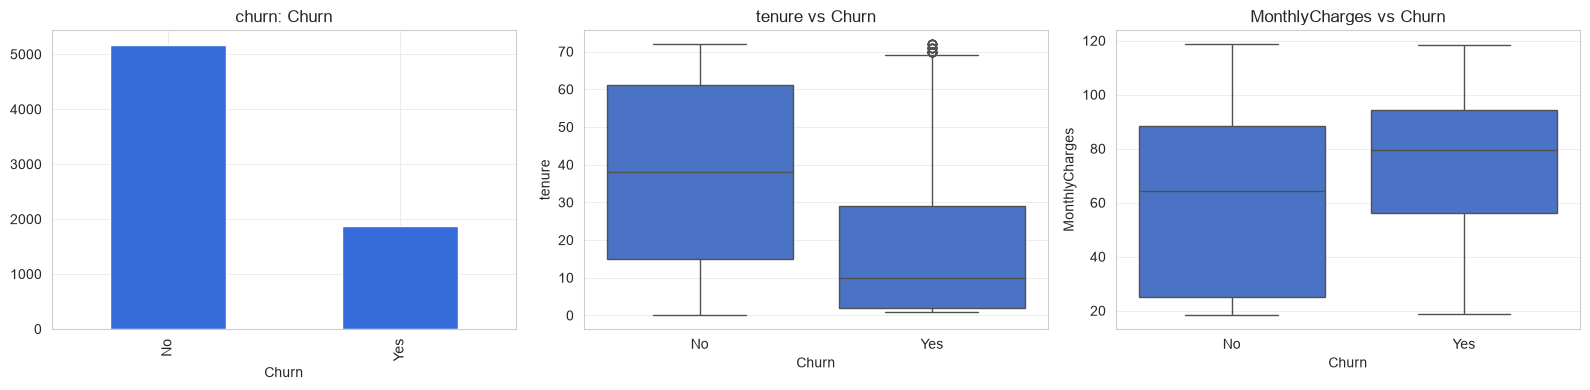

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_churn['Churn'].value_counts().plot(kind='bar', ax=axes[0], title='churn: Churn')
sns.boxplot(data=df_churn, x='Churn', y='tenure', ax=axes[1])
axes[1].set_title('tenure vs Churn')
sns.boxplot(data=df_churn, x='Churn', y='MonthlyCharges', ax=axes[2])
axes[2].set_title('MonthlyCharges vs Churn')

plt.tight_layout()
plt.show()

## Визуализация: demand

Временной ряд суммарных продаж по дням.
Ищем тренд и сезонность - это подтверждает необходимость лагов
и TimeSeriesSplit.

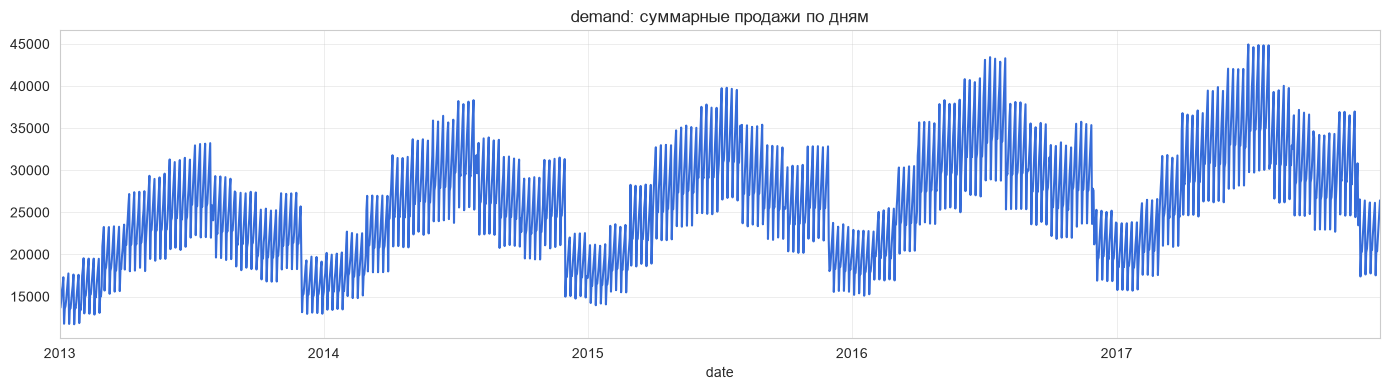

In [9]:
demand_dates = pd.to_datetime(df_demand['date'])
daily = df_demand.groupby(demand_dates)['sales'].sum()

daily.plot(figsize=(14, 4), title='demand: суммарные продажи по дням')
plt.tight_layout()
plt.show()

## Выводы EDA

- **credit**: 32 581 × 12, дисбаланс 78.2 / 21.8.
  - Пропуски: `person_emp_length` (895) и `loan_int_rate` (3 116).
  - Пропуск стажа **информативен**: доля дефолтов среди таких клиентов заметно выше средней -> строки не удаляем, добавляем флаг пропуска.
  - Невозможные значения: возраст > 100 (5 строк: 123, 144), стаж 123 года (2 строки) -> превращаем в `NaN` и заполняем.
  - 165 полных дубликатов строк -> удаляем до разбиения.
- **churn**: 7 043 × 21, дисбаланс 73.5 / 26.5.
  - `TotalCharges` хранится как текст из-за 11 пустых значений; у всех них `tenure = 0` (новые клиенты).
  - `customerID` - идентификатор, не признак.
- **demand**: 913 000 × 4 = 500 пар (store, item) × 1 826 дней, сетка полная.
  - Временной ряд с годовой и недельной сезонностью и ростом по годам (график выше).
  - Одна строка с `sales = 0` - важно для MAPE.

Препроцессинг для каждого датасета - в ноутбуках 02_credit, 03_churn, 04_demand.